:::{admonition} Run this notebook yourself!
:class: important

Download the executed notebook: **{nb-download}`ds_index.ipynb`**!

Run it in your browser: **{binder}`ds_index.ipynb`**!

:::

(datasaurus-index)=
# Using Penalized Metamer Synthesis to Recreate the Datasaurus Dozen

:::{admonition} Penalty function usage
:class: warning

These pages assume familiarity with the basics of using penalty function in metamer synthesis, as shown in the [](how-to-penalty) notebook.

:::

This section demonstrates how penalty functions affect the model metamers plenoptic synthesizes using a simple but non-trivial (and fun) problem: recreating the datasets from the Datasaurus dozen. In one of these notebooks ([plenoptic-logo](ds-plenoptic-logo)), we also demonstrate how different optimizers and redundant statistics affect the synthesis process and resulting metamers. These examples additionally show how plenoptic can be used for a very different problem than most of our examples, which focus on human perception.

In this notebook, we explain what the datasaurus dozen is, visualize the original datasets, implement a model to compute the relevant statistics, and demonstrate that these datasets are all metamers for that model. We will then demonstrate how plenoptic can be used to find new metameric datasets and visualize a new set synthesized by plenoptic's {class}`~plenoptic.Metamer` using the {attr}`~plenoptic.Metamer.penalty_function` argument to steer synthesis towards visually-interesting results.

After this notebook, you should read [](ds-general-principles) and [the example notebooks](ds-examples) series, which demonstrate how to synthesize each of our metameric datasets individually.

:::{contents}
:local:
:::

:::{toctree}
:maxdepth: 1
:hidden:

general_principles.md
ds_examples.md
:::

## The Datasaurus dozen

The [Datasaurus dozen](https://en.wikipedia.org/wiki/Datasaurus_dozen) consists of thirteen datasets with very different visual appearances but nearly-identical simple descriptive statistics. It was created by {cite:alp}`Matejka2017-same-stats` to highlight the importance of visualizing your data and was inspired by the earlier [Anscombe's Quartet](https://en.wikipedia.org/wiki/Anscombe's_quartet).

These datasets all consist of 142 `(x, y)` points, and all have the same mean and standard deviation (for both x and y; $\bar{x},\bar{y}$ and $\sigma_x,\sigma_y$), correlation between x and y ($r$), linear regression line (with parameters $\beta_0,\beta_1$), and coefficient of determination ($R^2$) for that linear regression.

This problem can be reframed in plenoptic's terms: if we define a differentiable model:

$$ M(\vec{x},\vec{y})=[\bar{x},\bar{y},\sigma_x,\sigma_y,r,\beta_0,\beta_1,R^2] $$

then the datasets of the Datasaurus dozen are all metamers of $M$: different inputs, identical outputs. This view lets us generate new datasets with metamer synthesis. Below, we'll compare this approach with the original method, and see how this change of perspective turns a seemingly hard problem into a relatively straightforward one: synthesis takes care of matching the statistics, and a simple penalty function describing the desired shape takes care of making each dataset distinct.

In [1]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import torch

import plenoptic as po

# use one of our helper functions for making videos.
from plenoptic.plot.display import _update_stem

# so that relative sizes of axes created by po.plot.imshow and others look right
plt.rcParams["figure.dpi"] = 72

plt.rcParams["animation.html"] = "html5"
# use single-threaded ffmpeg for animation writer
plt.rcParams["animation.writer"] = "ffmpeg"
plt.rcParams["animation.ffmpeg_args"] = ["-threads", "1"]
plt.rcParams["savefig.bbox"] = "tight"

We have downloaded the original datasaurus dozen from [OpenIntro](https://www.openintro.org/data/index.php?data=datasaurus) and reformatted it as a torch tensor of shape `(13, 2, 142)`, with an accompanying numpy array specifying the names of each dataset. These can be downloaded using {func}`plenoptic.data.fetch_data` and then loaded in using numpy and torch:

In [2]:
datasaurus_tarball = po.data.fetch_data("datasaurus.tar.gz")
data = torch.load(datasaurus_tarball / "datasaurus.pt")
categories = np.load(datasaurus_tarball / "categories.npy", allow_pickle=True)

The following cell defines helper functions to visualize and animate the datasets and their representation. The specifics are not important for our purposes, but if you're interested, you can expand the following cell to see their implementations:

In [3]:
def single_scatter(xy, ax, title=None, xlim=(0, 100), ylim=(0, 100), **scatter_kwargs):
    ax.scatter(*xy, **scatter_kwargs)
    if title is not None:
        ax.set_title(title)
    ax.set_aspect(1)
    ax.set(xlim=xlim, ylim=ylim)
    ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(1))
    ax.xaxis.set_minor_locator(mpl.ticker.AutoLocator())
    ax.yaxis.set_major_locator(mpl.ticker.MaxNLocator(1))
    ax.yaxis.set_minor_locator(mpl.ticker.AutoLocator())
    return ax


def plot_datasaurus(data, categories, ax_size=2, scatter_kwargs=None, fig=None):
    if scatter_kwargs is None:
        scatter_kwargs = {}
    n_rows = min(3, len(data) - 1)
    n_cols = int(max(np.ceil((len(data) - 1) / n_rows + 1), 2))
    if fig is None:
        fig = plt.figure(
            figsize=(ax_size * n_cols, ax_size * n_rows), layout="compressed"
        )
    axes = fig.subplots(n_rows, n_cols, sharex=True, sharey=True, squeeze=False)
    if n_rows == 1:
        dino_ax = axes[0, 0]
    if n_rows > 1:
        dino_ax = axes[1, 0]
        axes[0, 0].set_visible(False)
    if n_rows > 2:
        axes[2, 0].set_visible(False)
    axes = [dino_ax] + [ax for ax in axes[:, 1:].T.flatten()]
    for xy, title, ax in zip(data, categories, axes):
        single_scatter(xy, ax, title, **scatter_kwargs)
    for ax in axes[len(data) :]:
        ax.set_visible(False)
    return fig, axes


def update_datasaurus(data, axes):
    artists = []
    for d, ax in zip(data, axes):
        art = ax.collections[0]
        art.set_offsets(d.T)
        artists.append(art)
    return artists


def single_pair_plot(fig, gs, idx, wspace, xy, rep, title, rep_ylims):
    sgs = gs[idx[0], idx[1]].subgridspec(1, 3, width_ratios=[8, 5, 3], wspace=wspace)
    data_ax = fig.add_subplot(sgs[0])
    single_scatter(xy, data_ax)
    rep_ax = [fig.add_subplot(sgs[j]) for j in [1, 2]]
    rep_ax[0].set_title(title, size="x-large", x=0)
    rep_ax = model.plot_representation(rep, rep_ax)
    model.plot_representation(rep_data[0], rep_ax, "lines")
    for j, (ax, ylim) in enumerate(zip(rep_ax, rep_ylims)):
        ax_ylim = ax.get_ylim()
        rep_ylims[j] = [min(ax_ylim[0], ylim[0]), max(ax_ylim[1], ylim[1])]
    return data_ax, rep_ax, rep_ylims


def paired_plot(
    data, model, titles=[], ax_size=2, rep_aspect=1.3, plot_all=False, fig=None
):
    if not plot_all:
        n_cols = len(data)
        n_rows = 1
        height_factor = 1
        first_ax_row = 0
    else:
        n_rows = 3
        n_cols = int(np.ceil((len(data) - 1) / n_rows + 1))
        height_factor = 1.2
        first_ax_row = 1
    if fig is None:
        fig = plt.figure(
            figsize=(2.5 * ax_size * n_cols, height_factor * n_rows * ax_size),
            layout="compressed",
        )
    gs = fig.add_gridspec(
        n_rows, n_cols, wspace=0.1, hspace=0.4, width_ratios=[1.1] + (n_cols - 1) * [1]
    )
    rep_data = model(data)
    rep_ylims = [[0, 0], [0, 0]]
    data_ax, rep_ax, rep_ylims = single_pair_plot(
        fig, gs, [first_ax_row, 0], 0.35, data[0], rep_data[0], titles[0], rep_ylims
    )
    data_axes = [data_ax]
    rep_axes = [rep_ax]
    fig.set_layout_engine("none")
    for i, (xy, rep, title) in enumerate(zip(data[1:], rep_data[1:], titles[1:])):
        data_ax, rep_ax, rep_ylims = single_pair_plot(
            fig,
            gs,
            (i // (n_cols - 1), 1 + i % (n_cols - 1)),
            0.15,
            xy,
            rep,
            title,
            rep_ylims,
        )
        data_axes.append(data_ax)
        rep_axes.append(rep_ax)
        data_ax.set(yticklabels=[], xticklabels=[])
        for ax in rep_ax:
            ax.set(yticklabels=[])
    for axes in rep_axes:
        for ax, ylim in zip(axes, rep_ylims):
            ax.set_ylim(ylim)
    return fig, data_axes, rep_axes

(plot-datasaurus)=

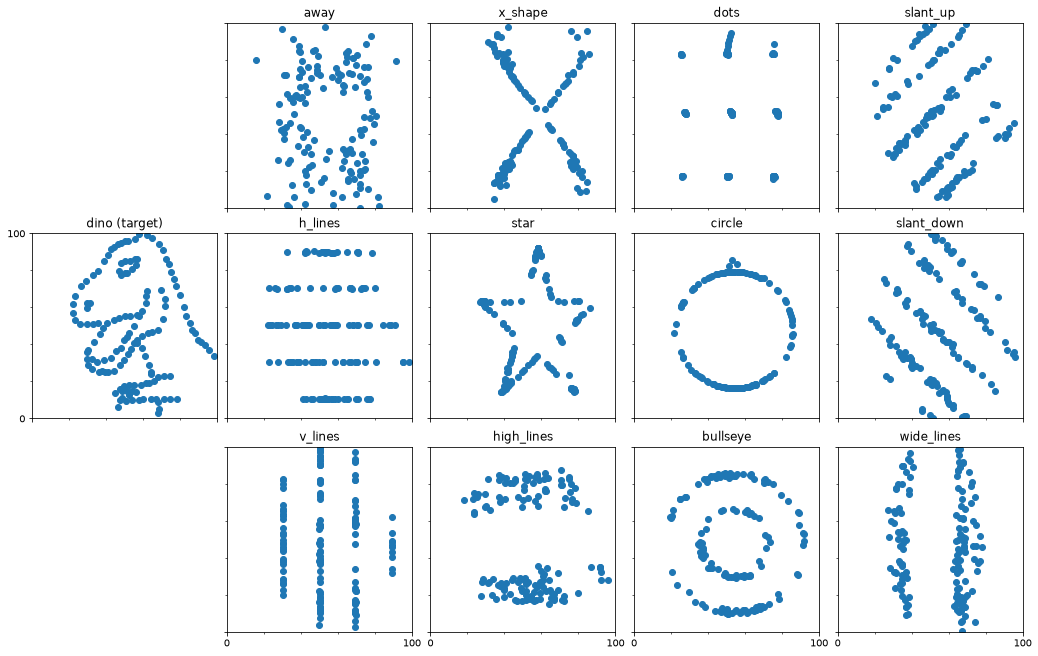

In [4]:
plot_datasaurus(data, categories, ax_size=3);

In the above figure, the leftmost subplot shows the original dino dataset. The other twelve subplots show each of the twelve metameric datasets from {cite:alp}`Matejka2017-same-stats`, as can also be seen in [the wikipedia article](https://en.wikipedia.org/wiki/Datasaurus_dozen).

The following cell defines the model that computes the summary statistics for us to match, as well as a `plot_representation` <!-- skip-lint --> method to visualize them. `DatasaurusModel` implements $M$, as defined above. Note that the statistics in $M$ are not all independent of each other; the final three statistics are redundant, but we include them because doing so seems to improve synthesis performance. See the dropdown below or more details.

In [5]:
class DatasaurusModel(torch.nn.Module):
    def __init__(self, n_pts=None, dtype=None, include_redundant_stats=True):
        """
        Create model to measure datasaurus stats.

        Parameters
        ----------
        n_pts
            Number of data points in the dataset we'll use the model for. Used to cache
            a corresponding vector of ones for computing linear regression.
        dtype
            dtype for the dataset we'll use the model for. Used to cache
            a corresponding vector of ones for computing linear regression.
        include_redundant_stats
            Whether to include the redundant stats (linear regression slope and
            intercept, coefficient of determination).
        """
        super().__init__()
        # cache ones to save time
        if n_pts is not None:
            self._ones = torch.ones(n_pts, dtype=dtype)
        else:
            self._ones = None
        self.include_redundant_stats = include_redundant_stats
        # This model has no trainable parameters, so it's always in eval mode
        self.eval()

    def _prepare_X(self, x):
        """Append vector of ones to matrix for linear regression (for intercept)."""
        ones = self._ones if self._ones is None else torch.ones_like(x)
        return torch.stack([ones, x], -1)

    def _compute_linreg(self, x, y):
        """Compute linear regression (with intercept) between x and y."""
        X = self._prepare_X(x)
        # unsqueezing and squeezing needed because of https://github.com/pytorch/pytorch/issues/158169
        return torch.linalg.lstsq(X, y.unsqueeze(-1)).solution.squeeze()

    def _compute_coeff_determination(self, x, y, solution):
        """Compute R^2 for linera regression fit."""
        X = self._prepare_X(x)
        pred_y = torch.einsum("x, n x -> n", solution, X)
        ss_res = (y - pred_y).pow(2).sum()
        ss_tot = (y - y.mean()).pow(2).sum()
        return 1 - (ss_res / ss_tot)

    def _vmap_coeff_determination(self, x, solution):
        """vmap _compute_coeff_determiniation across dim=0."""
        f = torch.func.vmap(lambda x, solt: self._compute_coeff_determination(*x, solt))
        return f(x, solution).unsqueeze(-1)

    def forward(self, data):
        """Compute summary statistics on data."""
        if data.ndim == 2:
            data = data.unsqueeze(0)
        elif data.ndim != 3:
            raise ValueError("data must be 2 or 3d!")
        stats = []
        stats.append(data.mean(-1))
        stats.append(data.std(-1))
        if self.include_redundant_stats:
            solution = torch.func.vmap(lambda x: self._compute_linreg(*x))(data)
            stats.append(solution)
        crosscorr = torch.func.vmap(lambda x: torch.corrcoef(x)[0, 1])(data)
        stats.append(crosscorr.unsqueeze(-1))
        if self.include_redundant_stats:
            stats.append(self._vmap_coeff_determination(data, solution))
        return torch.cat(stats, -1)

    def plot_representation(self, data, ax=None, style="stem", figsize=(6, 3)):
        """
        Plot model representation of data.

        We plot the representation as stem plots (if style=="stem") or dashed
        horizontal lines (if style=="lines"), on two separate sub-axes. The grouping
        is determined by their approximate magnitude in the original dino dataset. The
        first contains ["x mean", "y mean", "x std", "y std", "linreg intercept"], while
        the second contains ["linreg slope", "correlation", and "R^2"].

        Parameters
        ----------
        data: torch.Tensor
            The data to show on the plot. Should look like the output of
            forward, with the exact same structure.
        ax: plt.Axes or None
            Axes where we will plot the data. If a plt.Axes instance, will
            subdivide into 2 new axes. If None, we create a new figure.
        style: {"stem", "lines"}
            If "stem", plot data as stem plot. If "lines", plot as dashed
            horizontal lines.
        figsize: tuple[int]
            The size of the figure to create. Ignored if ax is not None.

        Returns
        -------
        axes
            List of two axes containing the subplots.
        """
        data = po.to_numpy(data).squeeze()
        # Set up grid spec
        if ax is None:
            # we add 2 to order because we're adding one to get the
            # number of orientations and then another one to add an
            # extra column for the mean luminance plot
            fig = plt.figure(figsize=figsize, layout="constrained")
            gs = mpl.gridspec.GridSpec(1, 2, fig, width_ratios=[5, 3], wspace=0.35)
            axes = [fig.add_subplot(gs[0, i]) for i in range(2)]
        elif isinstance(ax, mpl.axes.Axes) or len(ax) == 1:
            # want to make sure the axis we're taking over is basically invisible.
            ax = po.plot.display._clean_up_axes(
                ax, False, ["top", "right", "bottom", "left"], ["x", "y"]
            )
            gs = ax.get_subplotspec().subgridspec(
                1, 2, width_ratios=[5, 3], wspace=0.35
            )
            fig = ax.figure
            axes = [fig.add_subplot(gs[0, i]) for i in range(2)]
        else:
            axes = ax
            fig = axes[0].figure

        labels = [
            r"$\bar{x}$",  # noqa: RUF027
            r"$\bar{y}$",  # noqa: RUF027
            r"$\sigma_x$",
            r"$\sigma_y$",
            r"$\beta_0$",
            r"$\beta_1$",
            "$r$",
            "$R^2$",
        ]
        cutoff = 5
        linewidth = 1
        for i, ax in enumerate(axes):
            if i == 0:
                slicer = slice(0, cutoff)
            elif i == 1:
                slicer = slice(cutoff, len(labels) + 1)
            y = data[slicer]
            labs = labels[slicer]
            x = np.arange(len(labs))

            if style == "stem":
                ax.stem(y)
            elif style == "lines":
                ax.hlines(y, x - linewidth / 2, x + linewidth / 2, "k", "--")
            ax.set_xticks(x, labs)
            ax.yaxis.set_major_locator(mpl.ticker.MaxNLocator(1))
            ax.yaxis.set_minor_locator(mpl.ticker.AutoLocator())
        return axes

(datasaurus-redundant-stats)=
:::{admonition} Redundant statistics
:class: dropdown note

Our `DatasaurusModel` contains redundant statistics: the slope and intercept of the best-fit line and the corresponding coefficient of determination provide no additional constraints over the other five statistics. This is because they can be computed directly from the other statistics:
- The slope of the best-fit line [can be written as](https://en.wikipedia.org/wiki/Simple_linear_regression#Formulation_and_computation): $\beta_1=\frac{\sum_i(x_i-\bar{x})(y_i-\bar{y})}{\sum_i(x_i-\bar{x})^2}=\frac{\mathrm{cov}(x,y)}{\sigma_x^2}=r\frac{\sigma_y}{\sigma_x}$, where $\mathrm{cov}(\vec{x},\vec{y})$ is the covariance of $\vec{x}$ and $\vec{y}$.
- The intercept of that line [can be written as](https://en.wikipedia.org/wiki/Simple_linear_regression#Formulation_and_computation): $\beta_0=\bar{y}-\beta_1\bar{x}=\bar{y}-r(\frac{\sigma_y}{\sigma_x})\bar{x}$
- For [linear least squares with an intercept and slope](https://en.wikipedia.org/wiki/Coefficient_of_determination#As_squared_correlation_coefficient), $R^2=r^2$, the squared Pearson correlation coefficient.

Thus, matching $[\bar{x},\bar{y},\sigma_x,\sigma_y,r]$ also matches $[\beta_0,\beta_1,R^2]$. However, in practice, we find that including those redundant statistics in the model makes the optimization easier: it converges faster and results in a solution that better balances the metamer loss and penalty. See [plenoptic-logo](ds-plenoptic-logo) for a demonstration, and try it on other datasets for yourself! We have noticed that the reduced model finds good solutions for the simpler penalties such as [](ds_circle.md) and [](ds_away.md), and has difficulty for the more complex ones such as [](ds_slantup.md) and [](ds_vwidelines.md).

See [](ps-mag-means) for a similar example and discussion for the {class}`~plenoptic.models.PortillaSimoncelli` model.

:::

Now that we have the model, we can do two things: we can create a plot showing the values of each of these statistics, and we can compute the corresponding error. Once we compute the error, we can sort the datasets by their error. Below, we plot the dino (the target for metamer synthesis), and best and worst metamers:

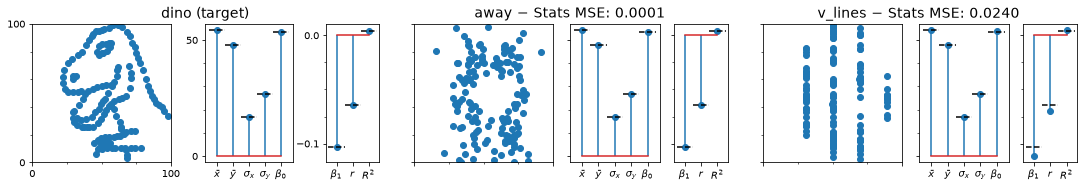

In [6]:
# Initialize the model
model = DatasaurusModel(data.shape[1], data.dtype)
# Compute the statistics for each dataset
rep_data = model(data)
target = rep_data[0].unsqueeze(0)
# Compute the MSE between the statistics on the target and each of the original datasets
met_mse = (target - rep_data).pow(2).mean(-1)
# Sort the data, titles, and error by the error
order = torch.argsort(met_mse)
data = data[order]
categories = categories[order]
met_mse = met_mse[order]
titles = np.asarray(
    [categories[0]]
    + [f"{c} $-$ Stats MSE: {e:.4f}" for c, e in zip(categories[1:], met_mse[1:])]
)

# Plot the target, best and worst metamer.
idx = [0, 1, -1]
paired_plot(data[idx], model, titles[idx], 2.5);

In [7]:
from myst_nb import glue

best_dataset = categories[1]
worst_dataset = categories[-1]

glue("best_dataset", best_dataset, display=False)
glue("worst_dataset", worst_dataset, display=False)

The above shows, from left to right, the target, the best metamer ({glue}`best_dataset`) and the worst metamer ({glue}`worst_dataset`). For each, we show the dataset and its model output as two stem plots, split by magnitude: $\bar{x},\bar{y},\sigma_x,\sigma_y,\beta_0$ in the first and $\beta_1,r,R^2$ in the second. Dashed horizontal lines show the dino's values.

From these three plots, we can see that {glue}`best_dataset` is a very good match on all statistics, whereas {glue}`worst_dataset` is a reasonable match, but has some error on the slope and correlation (if we double-check [the wikipedia page](https://en.wikipedia.org/wiki/Datasaurus_dozen), we can see that the accuracy is different for different statistics). This shows us that these dataset are all metamers for our `DatasaurusModel`. If you would like to see the corresponding plots for the remaining datasets, sorted by error, expand the following dropdown:

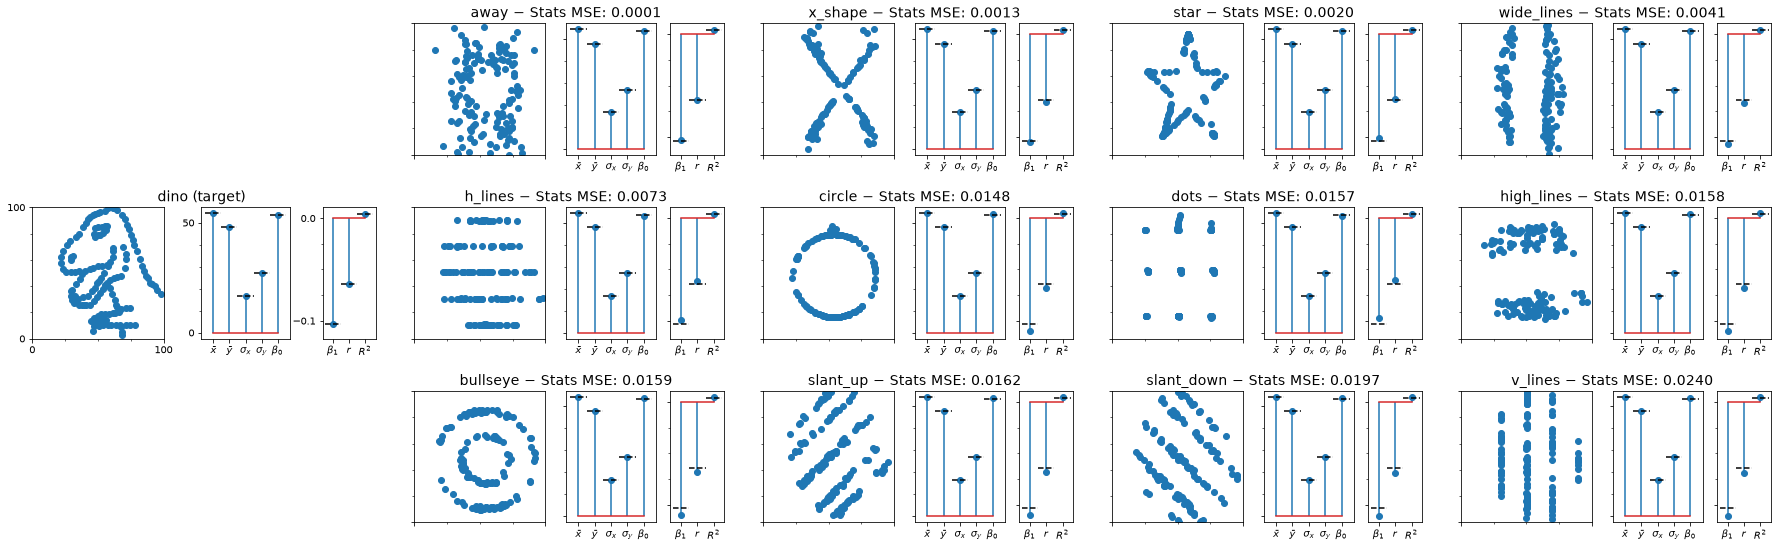

In [8]:
paired_plot(data, model, titles, 2.5, plot_all=True);

The authors of {cite:alp}`Matejka2017-same-stats` generated the datasets shown above using a [simulated annealing](https://en.wikipedia.org/wiki/Simulated_annealing) procedure: starting from the dino dataset, they applied small random perturbations to move the scatter plots closer to some target shape, while minimally affecting the original statistics. See paper for details.

This is a very different procedure than plenoptic's metamer synthesis! Importantly, the original procedure starts from the dino dataset and tries to change its appearance towards some target while preserving the intended statistics, while plenoptic's starts from any set of 142 `(x, y)` points and changes it so that its statistics match that of the dino dataset.

There is one additional wrinkle: as the authors point out, it's fairly straightforward to generate random datasets whose statistics match --- the difficulty lies in finding datasets that are "clearly different and identifiably distinct" while having the same statistical properties. As we'll show, in plenoptic this is accomplished by defining a penalty function which returns the distance from some intended shape.

## Using plenoptic to synthesize new metameric datasets

Using plenoptic, we can generate metameric datasets in a relatively straightforward manner, though note that even in this simple case, we have to tweak the penalty. As plenoptic was largely developed to work on images, the default {attr}`~plenoptic.Metamer.penalty_function` is {func}`~plenoptic.regularize.penalize_range` which, with its default values, encourages values to lie between 0 and 1. For this synthesis problem, we instead want the values to lie between 0 and 100, so we write a custom `penalty` which calls {func}`~plenoptic.regularize.penalize_range` while specifying an allowed range of `(0, 100)`.

In [9]:
# default penalty penalizes points whose values lie outside the (0, 1) range,
# so we need to specify we allow (0, 100) instead
def penalty(x):
    return po.regularize.penalize_range(x, (0, 100))


# data[0] is the dinosaur
met = po.Metamer(data[0], model, penalty_function=penalty)
# By default, we initialize metamer synthesis with points between 0 and 1. So the
# following initializes it with points randomly distributed between 0 and 100 instead.
# We also use the LBFGS optimizer, see plenoptic logo notebook for more details.
met.setup(initial_image=100 * torch.rand_like(data[0]), optimizer=torch.optim.LBFGS)
met.synthesize(20, store_progress=True)

/home/jenkins/agent/workspace/CCN_neurorse_plenoptic_main/lib/python3.12/site-packages/plenoptic/validate.py:101: UserWarning: plenoptic's methods have mostly been tested on 4d inputs with shape torch.Size([n_batch, n_channels, im_height, im_width]). They should theoretically work with different dimensionality; if you have any problems, please open an issue at https://github.com/plenoptic-org/plenoptic/issues/new?template=bug_report.md
  warnings.warn(
/home/jenkins/agent/workspace/CCN_neurorse_plenoptic_main/lib/python3.12/site-packages/plenoptic/validate.py:116: UserWarning: input_tensor range is (2.9487, 99.4872); plenoptic's methods have largely been tested with the range [0, 1]. Synthesis should still work, but if you have any problems, please open an issue.
  warnings.warn(
/home/jenkins/agent/workspace/CCN_neurorse_plenoptic_main/lib/python3.12/site-packages/plenoptic/validate.py:116: UserWarning: input_tensor range is (0.08593959243958782, 99.89376674617549); plenoptic's method

  0%|          | 0/20 [00:00<?, ?it/s]

In [10]:
# Initialize figure by plotting the first iteration
fig, axes = plt.subplots(
    1, 3, figsize=(8, 3), width_ratios=[5, 5, 3], layout="compressed"
)
plot_data = met.saved_metamer
ani_data = po.to_numpy(plot_data)
ani_rep = po.to_numpy(model(plot_data))
data_ax = single_scatter(ani_data[0], axes[0])

rep_axes = model.plot_representation(model(data)[0], axes[1:], "lines")
model.plot_representation(ani_rep[0], rep_axes)
fig.set_layout_engine("none")


# Update the data for each saved iteration.
def animate(i):
    data_ax.collections[0].set_offsets(ani_data[i].T)
    _update_stem(rep_axes[0].containers[0], ani_rep[i, :5])
    _update_stem(rep_axes[1].containers[0], ani_rep[i, 5:])


# In order to avoid this potentially taking a long time, make sure we animate at most 50
# frames
total_frames = 50
frame_step = max(len(plot_data) // total_frames, 1)
ani = mpl.animation.FuncAnimation(
    fig, animate, range(0, len(plot_data), frame_step), repeat=False
)
plt.close(fig)

# This will view the video if running in a jupyter notebook. If you are running outside
# of a notebook (e.g., in ipython), first save it and then open it with something that
# can view video files (e.g., your browser) by running: ani.save("ds_index.mp4")
ani

In the video above, the leftmost plot shows the metameric dataset over synthesis, while the right two show the model's representation at each stage (the horizontal lines show the representation of the dino, which is our target).

We can see that our synthesis procedure fairly quickly finds a metamer, starting from uniformly-distributed dots with x and y values between 0 and 100. However, the metamer doesn't look all that interesting: it still looks like a fairly random smattering of dots.

In order to find "clearly different and identifiably distinct" datasets, we need to do something more. Specifically, we can use {attr}`~plenoptic.Metamer.penalty_function` to bias the synthesis procedure. In this case, we can create penalty functions that encourage the dataset to have specific shapes. By passing them to {class}`~plenoptic.Metamer` at initialization, we can try to find datasets that are both `DatasaurusModel` metamers and "identifiably distinct".

## {attr}`~plenoptic.Metamer.penalty_function` steers synthesis towards interesting metamers

The [](ds-examples) demonstrate how to do this, for a wide variety of shapes. First, let's see what they look like. The following hidden cell loads in the cached metamers and creates a figure showing the datasets:

In [11]:
# for creating the plot
cached_metamers = []
# for animating the video
saved_metamers = []
# match order of initial data, plus our extras
titles = [
    "away",
    "hlines",
    "vlines",
    "xshape",
    "star",
    "hwidelines",
    "dots",
    "circle",
    "bullseye",
    "slantup",
    "slantdown",
    "vwidelines",
    "polygons",
    "oval",
    "plenoptic-logo",
]
metamer_tarball = po.data.fetch_data("datasaurus_metamers.tar.gz")
for t in titles:
    # synthesis for star is more complex and so it's saved slightly differently. see
    # its notebook for more details.
    f = metamer_tarball / f"datasaurus-{t}.pt"
    cached_metamers.append(torch.load(f)["_metamer"])
    if t == "star":
        f = metamer_tarball / f"datasaurus-{t}-saved.pt"
        saved_metamers.append(torch.load(f).detach())
    else:
        saved_metamers.append(torch.stack(torch.load(f)["_saved_metamer"]).detach())
cached_metamers = torch.stack([data[0], *cached_metamers])
titles = ["dino (target)"] + titles
saved_metamers = torch.stack(saved_metamers)

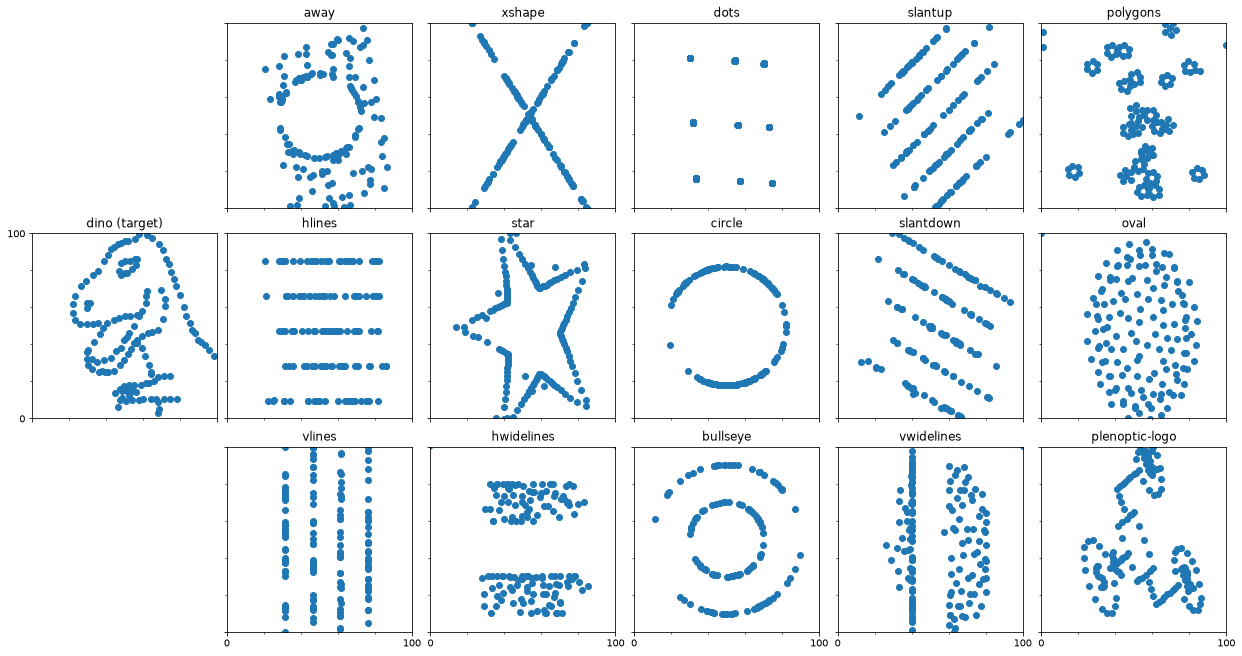

In [12]:
plot_datasaurus(cached_metamers, titles, 3);

As in the above plots, the leftmost subplot corresponds to our target, the dino dataset. Each of the remaining ones shows a distinct metameric dataset, with the top figure showing the datasets themselves, and the bottom showing their representation (with the dino's representation shown as dashed horizontal lines on each plot). Several things to note:

- The plots are laid out in the same order as above, with the addition of three extra datasets (in the rightmost column).
- The majority of these datasets start from randomly-distributed points between with x and y values between 0 and 1 and use {class}`torch.optim.LBFGS` to find a `DatasaurusModel` metamer for the dino dataset in 50 iterations with some custom penalty functions. The exceptions are:
    - [plenoptic-logo](ds-plenoptic-logo), which starts from a points arranged into the plenoptic logo and uses no penalty function. The procedure outlined in {cite:alp}`Matejka2017-same-stats` does not allow for arbitrary initialization, and we wished to present an example that does so.
    - [](ds_star.md) requires a more complex, two-stage synthesis procedure: first a star is synthesized with the same x and y mean as the dino dataset (no other statistics are considered). Then, the star constraint is removed and all of the `DatasaurusModel` statistics are matched.
- We are not intending to exactly match the original datasaurus dozen, but to demonstrate how one can use plenoptic to create similar datasets.

:::{admonition} What does successful metamer synthesis look like?
:class: note

In this case, successful synthesis results in datasets which are:
- metameric to the original datasaurus, i.e., the heads of their stem plots lie on the dashed horizontal lines.
- "clearly different and identifiably distinct" from the original dataset and each other.
- similar, but not necessarily identical, in appearance to the corresponding dataset from the original datasaurus dozen.

Importantly, we do **not** need to achieve a penalty value of zero in order for the synthesis to be successful! We are using the penalty function to bias the synthesis procedure, and do not necessarily need it to be completely satisfied, if the desiderata above are met.

:::

One fact which is not obvious from the above plot is that our datasets are a better metamers! The following bar plot shows the mean-squared error in the model statistics for the original and plenoptic-generated datasets. For each pair here both versions exist, the plenoptic dataset has a lower error! Hover over the bars below to see the two datasets plotted side-by-side and view the exact error.

:::{warning}
The following cell requires an additional package `altair`, which can be installed with `pip`.
:::

In [13]:
import altair as alt

# Compute the error for the plenoptic metamers
cached_rep = model(cached_metamers)
plen_met_mse = (cached_rep[:1] - cached_rep).pow(2).mean(-1)


# Map between the original names and the ones we use
def name_map(x):
    if x == "high_lines":
        x = "hwidelines"
    elif x == "wide_lines":
        x = "vwidelines"
    else:
        x = x.replace("_", "")
    return x


# Create the data object containing errors needed for Altair to plot. They also accept
# pandas dataframes, but that would be another dependency. We ignore the first entry in
# each of the following values because that corresponds to the target (which is
# identical in both and has zero error, by definition)
alt_data = [
    {"source": "original", "Stats MSE": m.item(), "dataset": name_map(c)}
    for m, c in zip(met_mse[1:], categories[1:])
]
alt_data += [
    {"source": "plenoptic", "Stats MSE": m.item(), "dataset": c}
    for m, c in zip(plen_met_mse[1:], titles[1:])
]
alt_data = alt.Data(values=alt_data)

# Create data object containing datasets
alt_points = []
for d, c in zip(po.to_numpy(data)[1:], categories[1:]):
    for x, y in d.T:
        alt_points.append(
            {"source": "original", "x": x, "y": y, "dataset": name_map(c)}
        )
for d, c in zip(po.to_numpy(cached_metamers)[1:], titles[1:]):
    for x, y in d.T:
        alt_points.append({"source": "plenoptic", "x": x, "y": y, "dataset": c})
alt_points = alt.Data(values=alt_points)

# Create altair chart
selection = alt.selection_point(
    fields=["dataset"], nearest=True, on="pointerover", empty=False, clear="pointerout"
)
base = alt.Chart(alt_data).encode(
    x=alt.X("dataset:N", sort=titles),
)
bars = (
    base.mark_bar()
    .encode(
        y=alt.Y("Stats MSE:Q"),
        color="source:N",
        xOffset="source:N",
    )
    .properties(
        width=alt.Step(18),
    )
)
tt = (
    base.transform_pivot("source", "Stats MSE", groupby=["dataset"])
    .mark_rule(strokeWidth=45)
    .encode(
        opacity=alt.when(selection).then(alt.value(0.3)).otherwise(alt.value(0)),
        tooltip=["original:Q", "plenoptic:Q"],
    )
    .add_params(selection)
)

scatter = (
    alt.Chart(alt_points, height=200, width=200)
    .mark_point(filled=True)
    .encode(
        x=alt.X("x:Q").scale(domain=(0, 100)),
        y=alt.Y("y:Q").scale(domain=(0, 100)),
        color=alt.Color("source:N"),
        column=alt.Column("source:N", title=""),
    )
    .facet(alt.Facet("dataset:N", title="", header=alt.Header(labelFontSize=0)))
    .transform_filter(selection)
)
((bars + tt) & scatter).configure(autosize=alt.AutoSizeParams(resize=True))

alt.VConcatChart(...)

In addition to plotting the final metameric datasets, we can also visualize the synthesis process as a video! The following is laid out the same as the figure above, and animates the datasets over the course of synthesis, starting from initialization:

In [14]:
init_metamers = torch.cat([data[:1], saved_metamers[:, 0]])
fig, data_axes = plot_datasaurus(init_metamers, titles, 3)
fig.set_layout_engine("none")

ani_data = po.to_numpy(saved_metamers)


# Update the data for each saved iteration.
def animate(frame):
    i = 0
    for dax in data_axes:
        if dax.get_title() in ["", "dino (target)"]:
            continue
        dax.collections[0].set_offsets(saved_metamers[i, frame].T)
        i += 1


# In order to avoid this potentially taking a long time, make sure we animate at most 50
# frames
total_frames = 50
frame_step = max(saved_metamers.shape[1] // total_frames, 1)
ani = mpl.animation.FuncAnimation(
    fig, animate, range(0, saved_metamers.shape[1], frame_step), repeat=False
)
plt.close(fig)

# This will view the video if running in a jupyter notebook. If you are running outside
# of a notebook (e.g., in ipython), first save it and then open it with something that
# can view video files (e.g., your browser) by running: ani.save("ds_index.mp4")
ani

## Next steps

- Read [](general_principles.md) for lessons that should help when developing your own penalty functions and applying them to your own problems.
- Read [](ds-examples) to see each of the examples in detail.